# The Ocean Cleanup: Multi-Criteria Decision Analysis (MCDA)

Four alternatives for removing plastic from the Great Pacific Garbage Patch (**Modular Fleet**, **Anchored Barrier Array**, **Autonomous Skimmer Vessels** and **System 03**) are rated by five stakeholder groups (The Ocean Cleanup, North Pacific commercial fishers, investors/donors, marine conservation advocates and citizens) on their own weighted criteria, using a preference scale from 0 (worst) to 100 (best). With Preference Function Modelling (PFM), the `a_fine_aggregator` combines the ratings in two levels: criteria into one score per stakeholder, then stakeholders into one group preference score per alternative. A sensitivity analysis repeats the second level for different stakeholder weights. All inputs are read from `MCDA_input/MCDA_Ratings_OceanCleanup_System03.csv`.

## Imports

In [25]:
# Import packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Round the float values in the dataframe to 2 decimal places
pd.options.display.float_format = '{:.2f}'.format

# Import local module for a-fine-aggregator
from genetic_algorithm_pfm.a_fine_aggregator import a_fine_aggregator

## Load ratings

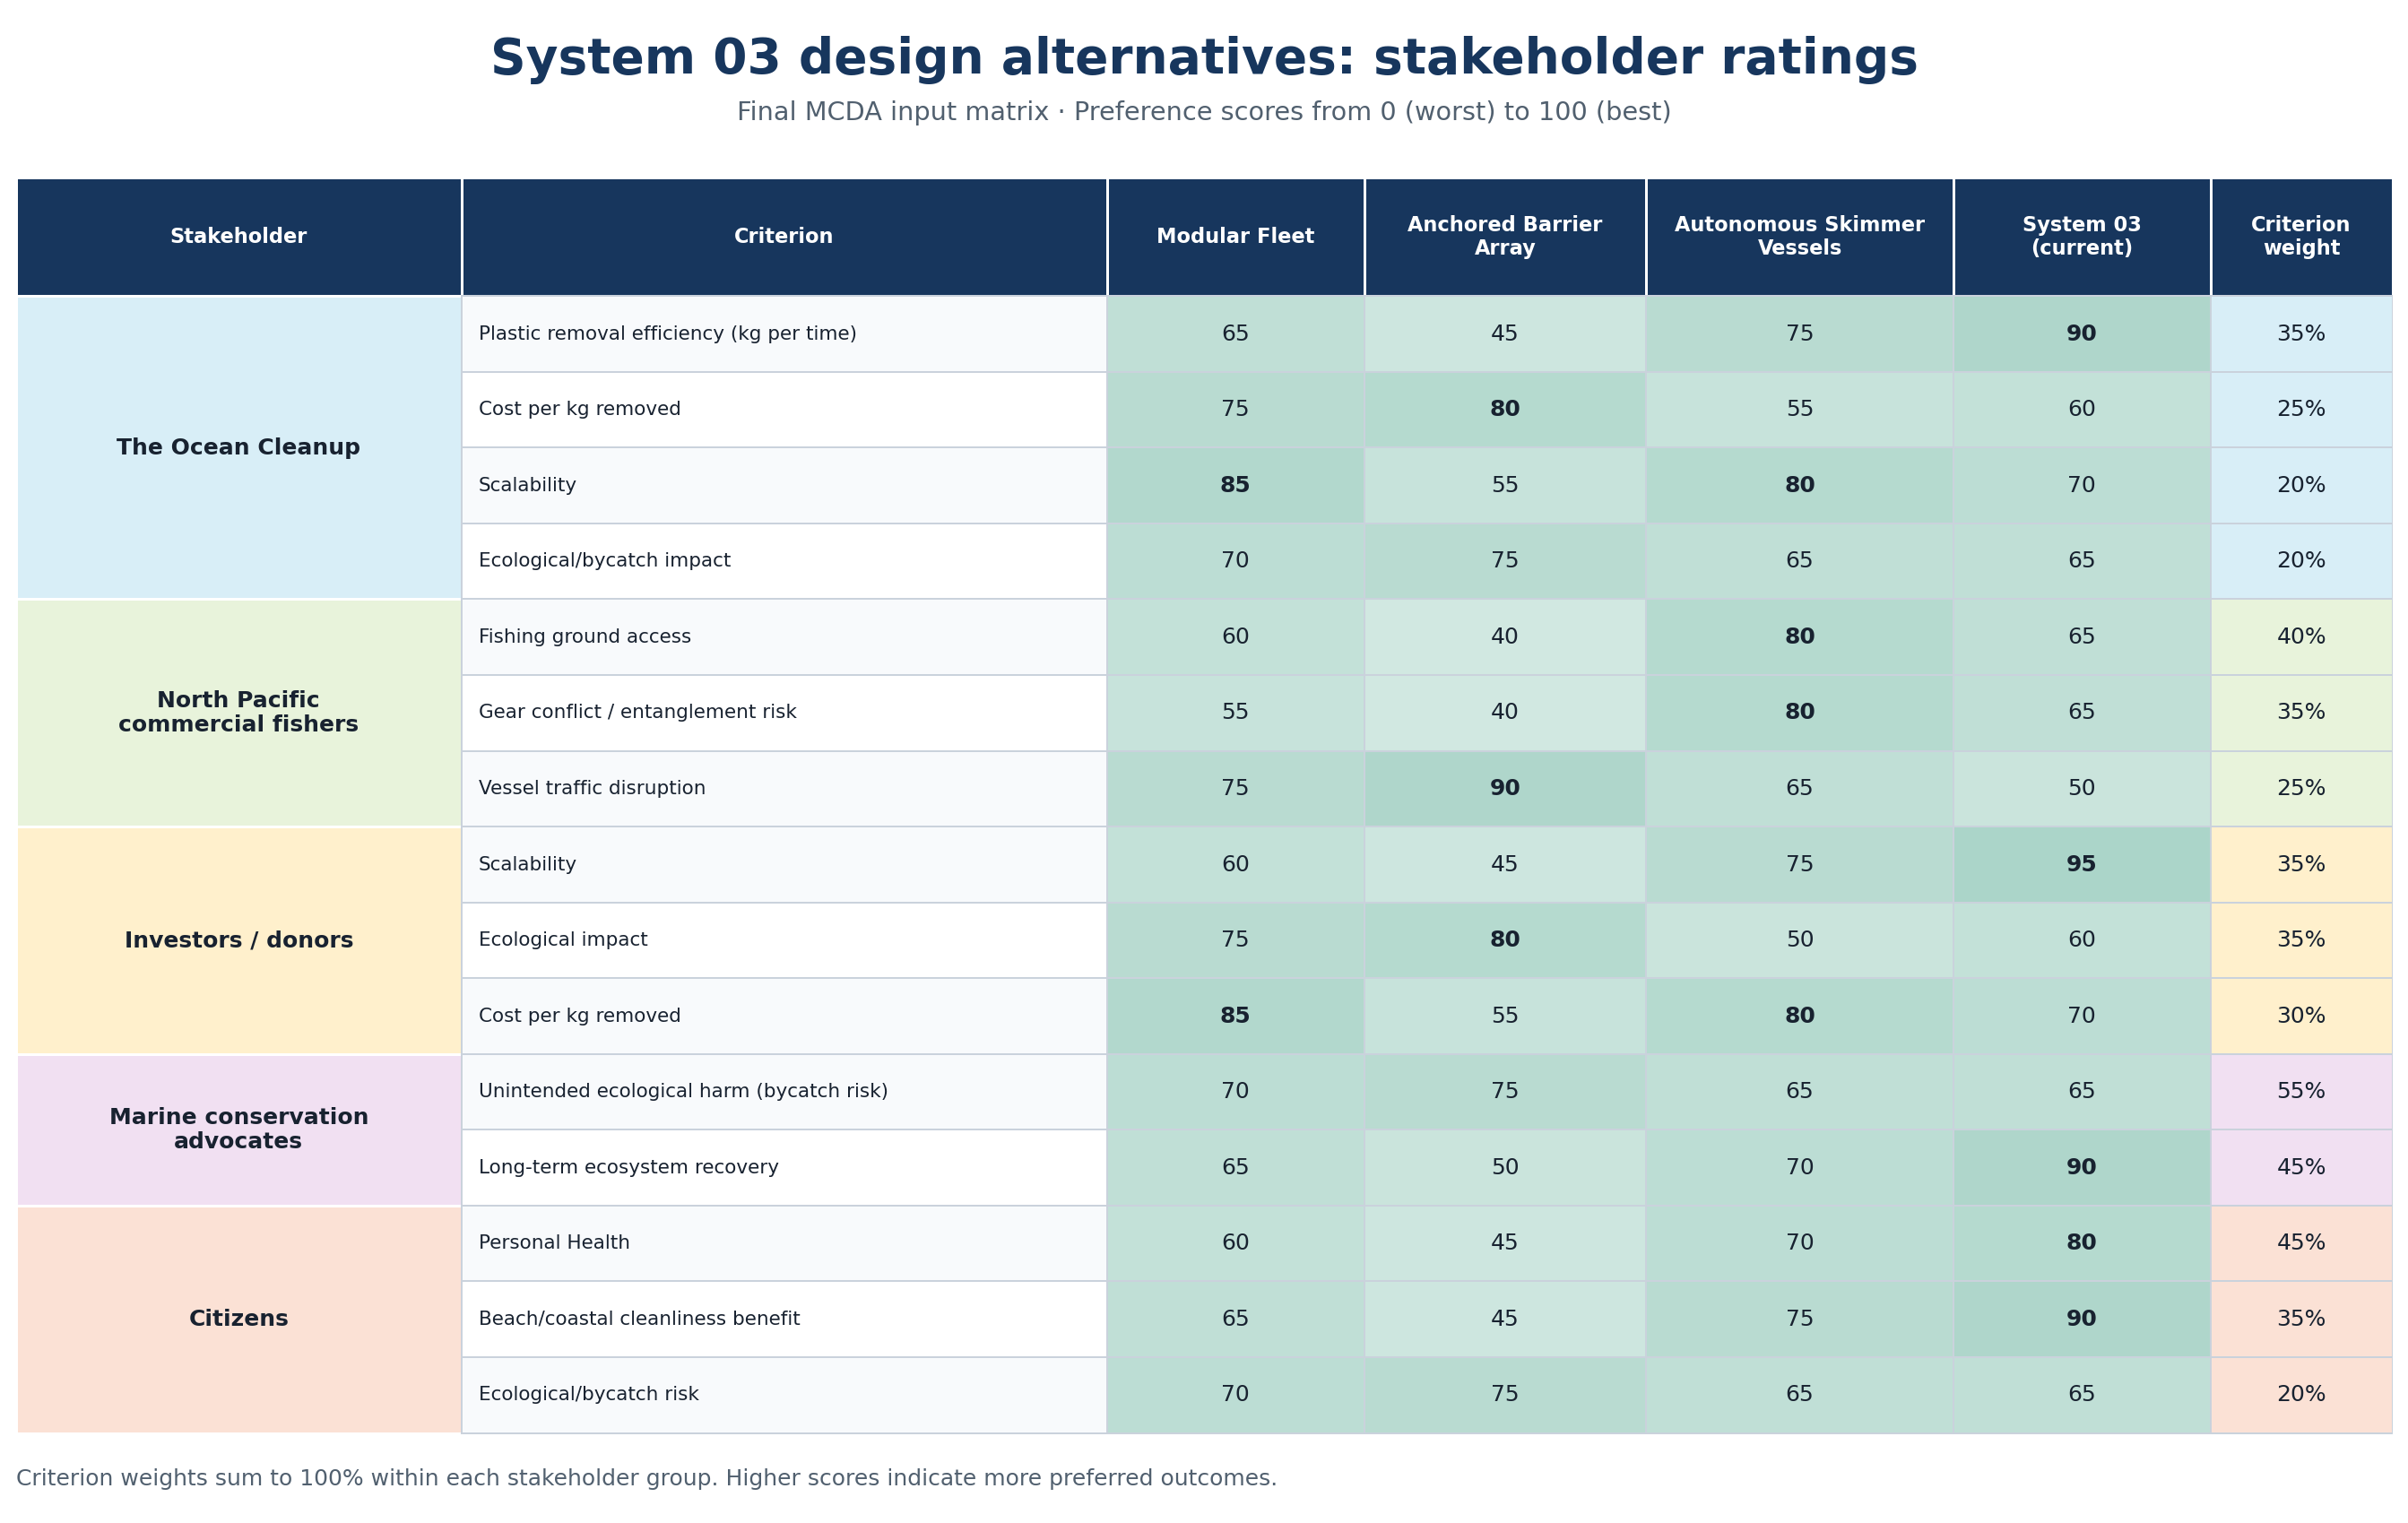

 ![MCDA_assessment (4).png](<attachment:MCDA_assessment (4).png>)
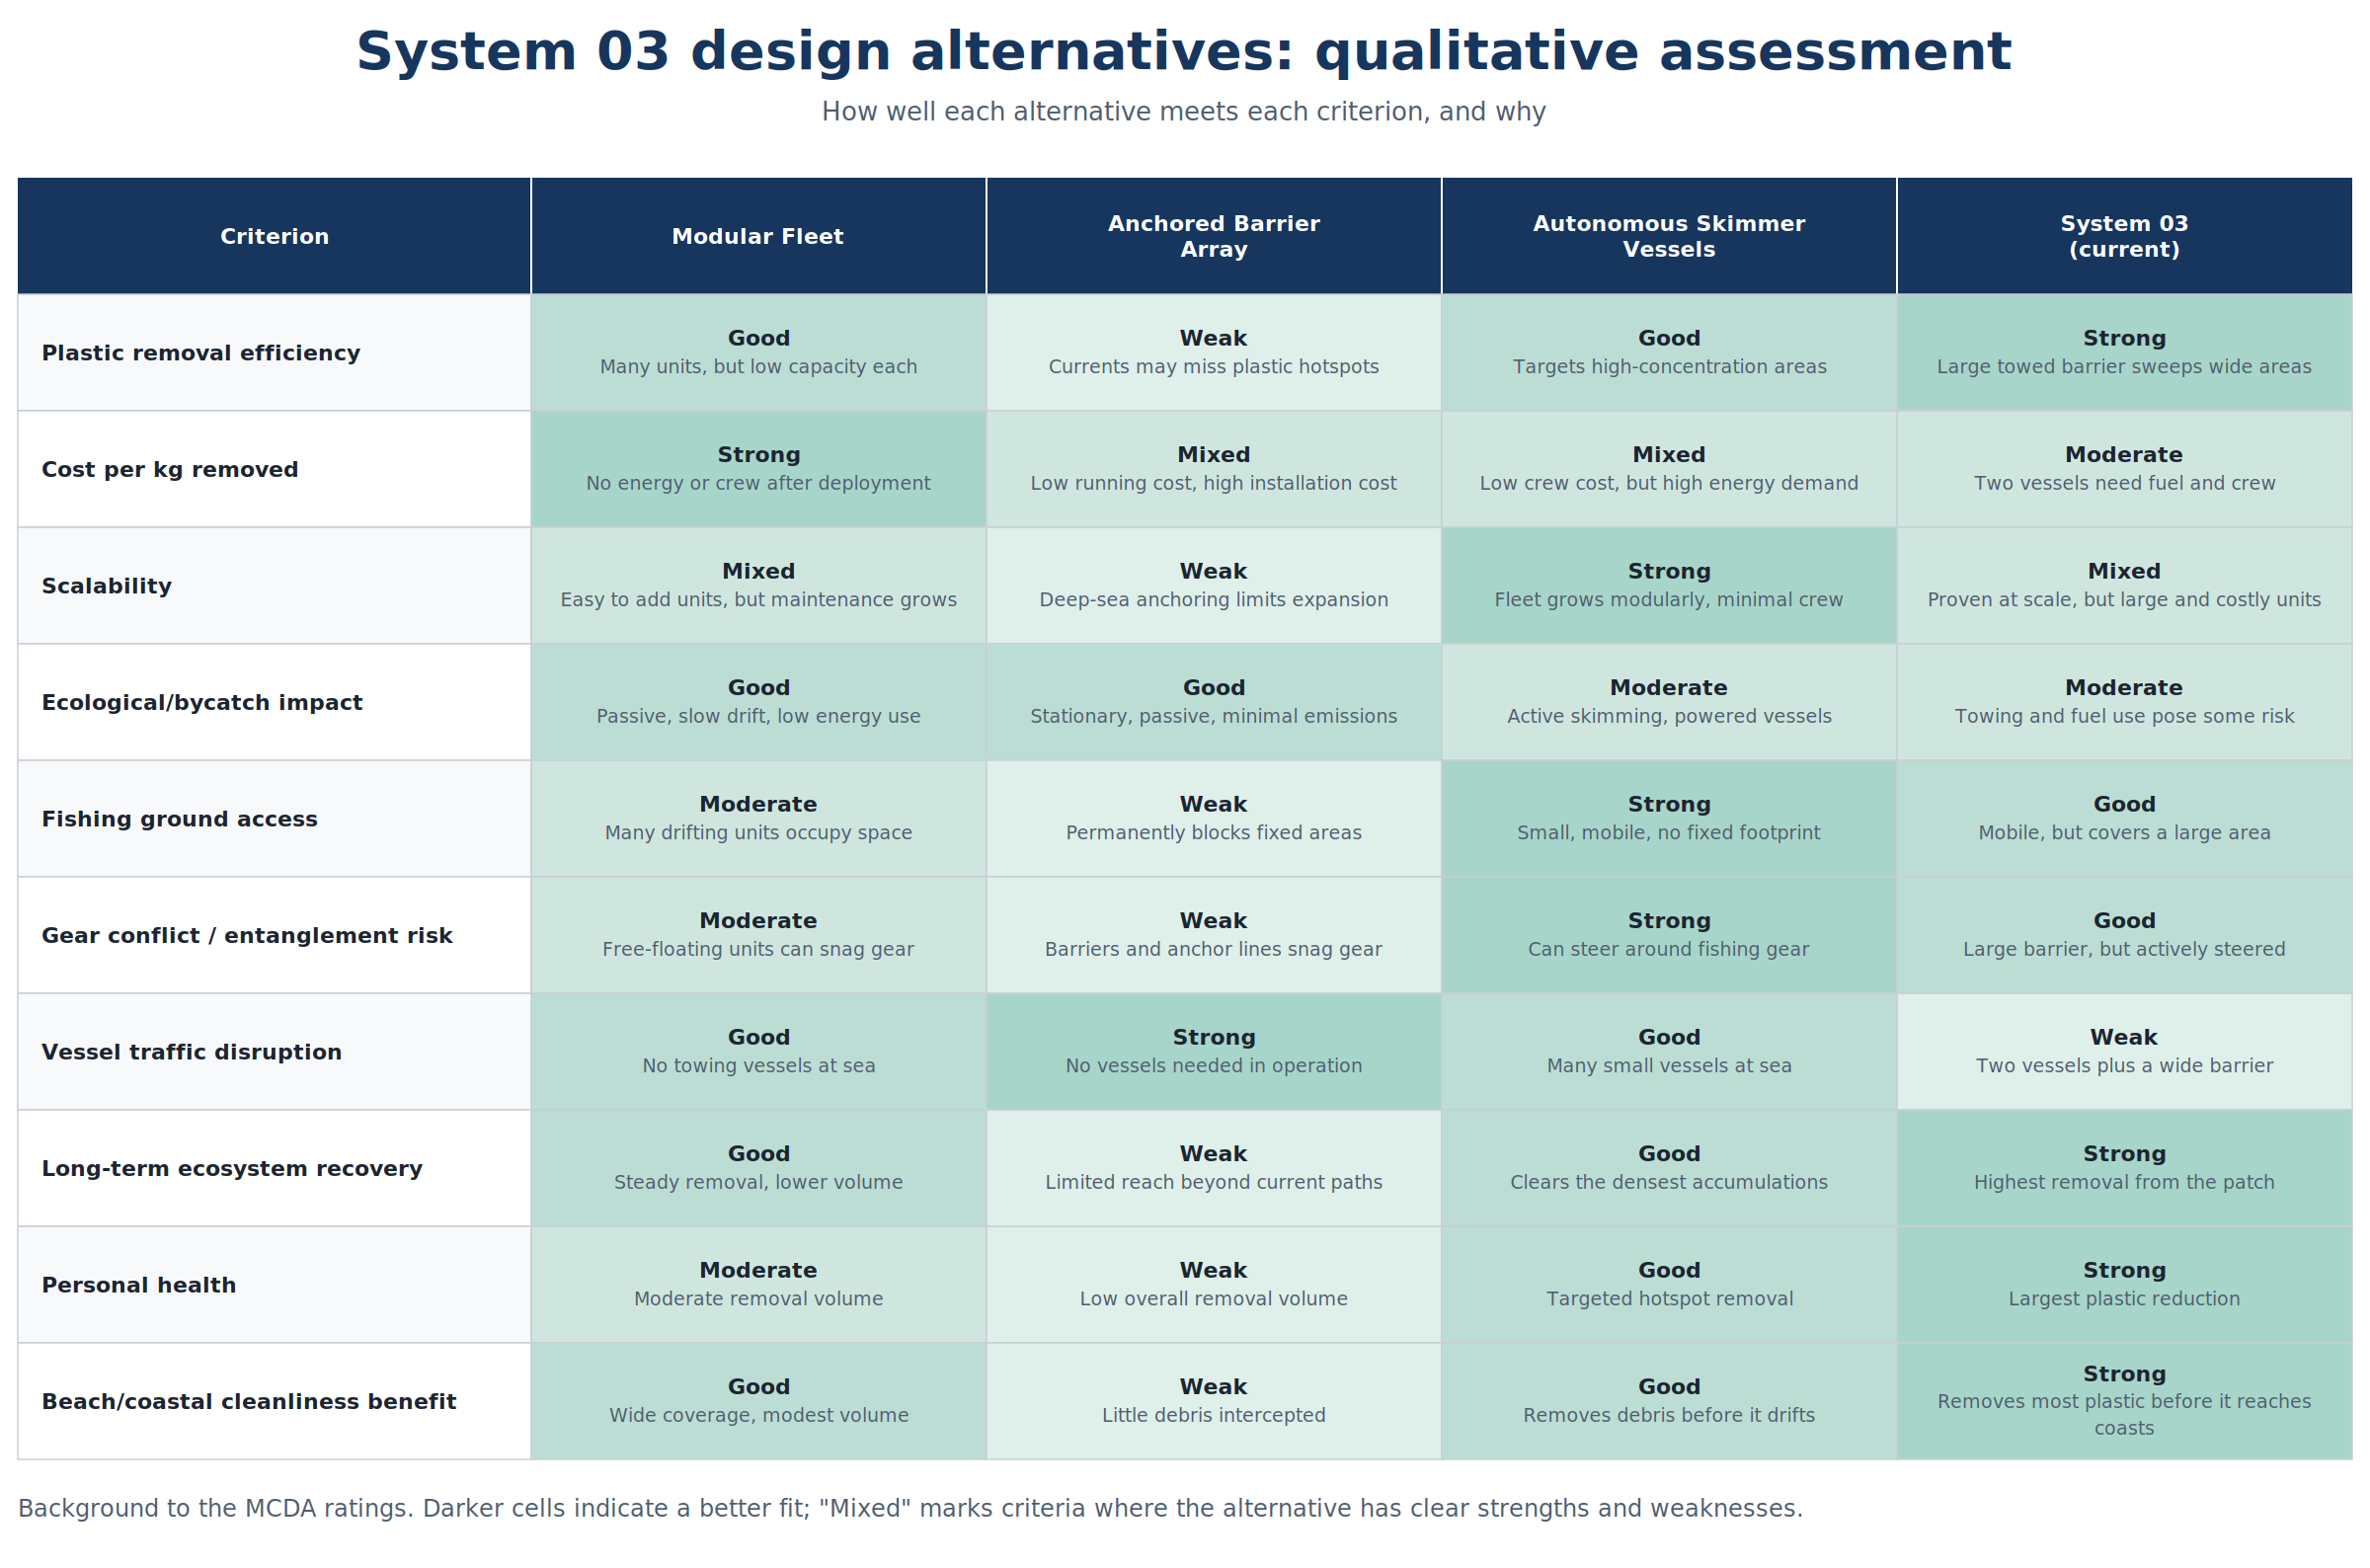

In [26]:
ratings = pd.read_csv(
    "MCDA_input/MCDA_Ratings_OceanCleanup_System03.csv",
    sep=";",       # fields are semicolon-separated, not comma-separated
    skiprows=1     # skip the  title row
)

alternatives = list(ratings.columns[2:-1].unique()) # Get the list of alternatives from the dataframe columns, excluding the first two and last column
stakeholders = list(ratings["Stakeholder"].unique()) # Get the list of stakeholders from the "Stakeholder" column in the dataframe
print(f"Alternatives: {alternatives}")
print(f"Stakeholders: {stakeholders}")
display(ratings)


Alternatives: ['Modular Fleet', 'Anchored Barrier Array', 'Autonomous Skimmer Vessels', 'System 03 (current)']
Stakeholders: ['The Ocean Cleanup', 'North Pacific commercial fishers', 'Investors/donors', 'Marine conservation advocates', 'Citizens']


,Stakeholder,Criteria,Modular Fleet,Anchored Barrier Array,Autonomous Skimmer Vessels,System 03 (current),Criteria_Weight
0,The Ocean Cleanup,Plastic removal efficiency (kg per time),65,45,75,90,0.35
1,The Ocean Cleanup,Cost per kg removed,75,80,55,60,0.25
2,The Ocean Cleanup,Scalability,85,55,80,70,0.20
3,The Ocean Cleanup,Ecological/bycatch impact,70,75,65,65,0.20
4,North Pacific commercial fishers,Fishing ground access,60,40,80,65,0.40
5,North Pacific commercial fishers,Gear conflict / entanglement risk,55,40,80,65,0.35
6,North Pacific commercial fishers,Vessel traffic disruption,75,90,65,50,0.25
7,Investors/donors,Scalability,60,45,75,95,0.35
8,Investors/donors,Ecological impact,75,80,50,60,0.35
9,Investors/donors,Cost per kg removed,85,55,80,70,0.30


## Check criteria weights

Each stakeholder's criteria weights must sum to 1.

In [27]:
# Check each stakeholder's weights sum to 1 (i.e. 100%)
print("Check weights per stakeholder:")
all_valid = True

for stakeholder in stakeholders:
    stakeholder_weights = ratings.loc[ratings["Stakeholder"] == stakeholder, "Criteria_Weight"]
    total = stakeholder_weights.sum()
    is_valid = np.isclose(total, 1)
    all_valid &= is_valid

    status = "OK" if is_valid else "MISMATCH"
    print(f"  {stakeholder:<40s}: {total:6.2f}  [{status}]")


Check weights per stakeholder:
  The Ocean Cleanup                       :   1.00  [OK]
  North Pacific commercial fishers        :   1.00  [OK]
  Investors/donors                        :   1.00  [OK]
  Marine conservation advocates           :   1.00  [OK]
  Citizens                                :   1.00  [OK]


## Stakeholder weights

Baseline: equal weights (0.2 each).

In [ ]:
# Set stakeholder weights
# Same stakeholder order as the weights in OceanCleanup_System03.ipynb
#               inv, TOC, fishers,cons,citizens
weights_eq =    [0.2, 0.2, 0.2, 0.2, 0.2]  # equal weights for stakeholders

stakeholder_weights = weights_eq 

assert np.isclose(sum(stakeholder_weights), 1), f"Weights must sum to 1, got {sum(stakeholder_weights)}"


## Aggregation

Level 1: criteria → stakeholder score. Level 2: stakeholders → group score. `scores_range=(-0.0, -100.0)` gives a 0–100 scale (negative because the aggregator minimises).

In [29]:
# Calculate the aggregated scores for each alternative using the a-fine-aggregator
# --- Level 1: aggregate criteria ratings -> one score per stakeholder per alternative ---
stakeholder_scores = {}

for stakeholder in stakeholders:
    stakeholder_data = ratings.loc[ratings["Stakeholder"] == stakeholder]
    criteria_weights = stakeholder_data["Criteria_Weight"].to_numpy()
    p = stakeholder_data[alternatives].to_numpy()  # shape: n_criteria x n_alternatives
    stakeholder_scores[stakeholder] = a_fine_aggregator(criteria_weights, p, scores_range=(-0.0, -100.0))

# Collect into matrix: rows = stakeholders, columns = alternatives (order matches `alternatives`)
stakeholder_score_matrix = np.array([stakeholder_scores[s] for s in stakeholders])

print("Individual stakeholder aggregated scores:")
display(pd.DataFrame(stakeholder_score_matrix, index=stakeholders, columns=alternatives))

# --- Level 2: aggregate stakeholder scores -> final preference score per alternative ---
final_scores = a_fine_aggregator(stakeholder_weights, stakeholder_score_matrix, scores_range=(-0.0, -100.0))

results = (
    pd.DataFrame(final_scores, index=alternatives, columns=["Preference score"])
    .round(2)
    .sort_values("Preference score", ascending=False)
)

print("Final aggregated preference scores per alternative:")
display(results)


Individual stakeholder aggregated scores:


,Modular Fleet,Anchored Barrier Array,Autonomous Skimmer Vessels,System 03 (current)
The Ocean Cleanup,100.00,1.66,0.00,44.69
North Pacific commercial fishers,40.13,0.00,100.00,37.16
Investors/donors,100.00,0.00,37.04,81.48
Marine conservation advocates,72.54,100.00,0.00,90.18
Citizens,41.73,0.00,60.62,100.00


Final aggregated preference scores per alternative:


,Preference score
System 03 (current),100.00
Modular Fleet,97.70
Autonomous Skimmer Vessels,42.21
Anchored Barrier Array,0.00


## Sensitivity analysis: stakeholder weights

Three stakeholder-weight scenarios (equal, influence-based, environmental priority); criteria weights and ratings stay unchanged.

In [30]:
print(stakeholders)

['The Ocean Cleanup', 'North Pacific commercial fishers', 'Investors/donors', 'Marine conservation advocates', 'Citizens']


In [ ]:
# ---------------------------------------------------------
# Sensitivity analysis: stakeholder-weight scenarios
# Stakeholders are listed in the same order as the weights
# in OceanCleanup_System03.ipynb.
# ---------------------------------------------------------

sensitivity_scenarios = {

    "Baseline - Equal weights": {
        "Investors/donors": 0.20,
        "The Ocean Cleanup": 0.20,
        "North Pacific commercial fishers": 0.20,
        "Marine conservation advocates": 0.20,
        "Citizens": 0.20
    },

    "Influence-based weighting": {
        "Investors/donors": 0.225,
        "The Ocean Cleanup": 0.30,
        "North Pacific commercial fishers": 0.175,
        "Marine conservation advocates": 0.175,
        "Citizens": 0.125
    },

    "Environmental priority": {
        "Investors/donors": 0.15,
        "The Ocean Cleanup": 0.20,
        "North Pacific commercial fishers": 0.15,
        "Marine conservation advocates": 0.35,
        "Citizens": 0.15
    }
}

# Check that scenario stakeholder names match the notebook stakeholder names
for scenario_name, scenario_weights in sensitivity_scenarios.items():

    missing = set(stakeholders) - set(scenario_weights.keys())
    extra = set(scenario_weights.keys()) - set(stakeholders)

    if missing or extra:
        print(f"{scenario_name}:")
        print("  Missing stakeholders:", missing)
        print("  Extra stakeholders:", extra)

In [32]:
# Check that the weights in every scenario sum to 1.00

print("Stakeholder-weight validation:")

for scenario_name, scenario_weights in sensitivity_scenarios.items():

    total = sum(scenario_weights.values())
    valid = np.isclose(total, 1.0)

    status = "OK" if valid else "MISMATCH"

    print(f"{scenario_name:<30s}: {total:.3f} [{status}]")

    assert valid, f"{scenario_name} weights sum to {total}, not 1.0"

Stakeholder-weight validation:
Baseline - Equal weights      : 1.000 [OK]
Influence-based weighting     : 1.000 [OK]
Environmental priority        : 1.000 [OK]


In [33]:
# ---------------------------------------------------------
# Recalculate final preference scores for each scenario
# ---------------------------------------------------------

scenario_scores = {}
scenario_rankings = {}

for scenario_name, scenario_weights_dict in sensitivity_scenarios.items():

    # Put weights into the same order as the stakeholder_score_matrix
    scenario_weights = np.array([
        scenario_weights_dict[stakeholder]
        for stakeholder in stakeholders
    ])

    # Level 2 aggregation:
    # stakeholder scores -> overall group preference score
    scores = a_fine_aggregator(
        scenario_weights,
        stakeholder_score_matrix,
        scores_range=(-0.0, -100.0)
    )

    scenario_scores[scenario_name] = scores

    # Rank 1 = highest preference
    ranks = pd.Series(
        scores,
        index=alternatives
    ).rank(
        ascending=False,
        method="min"
    ).astype(int)

    scenario_rankings[scenario_name] = ranks

In [34]:
# ---------------------------------------------------------
# Compare preference scores across scenarios
# ---------------------------------------------------------

sensitivity_results = pd.DataFrame(
    scenario_scores,
    index=alternatives
).round(2)

print("Preference scores under each stakeholder-weight scenario:")
display(sensitivity_results)

Preference scores under each stakeholder-weight scenario:


,Baseline - Equal weights,Influence-based weighting,Environmental priority
Modular Fleet,97.70,100.00,95.87
Anchored Barrier Array,0.00,0.00,7.98
Autonomous Skimmer Vessels,42.21,29.88,0.00
System 03 (current),100.00,83.72,100.00


In [35]:
# ---------------------------------------------------------
# Ranking of the alternatives under each scenario
# Rank 1 = most preferred alternative;
# rank 4 = least preferred alternative.
# ---------------------------------------------------------

ranking_results = pd.DataFrame(
    scenario_rankings,
    index=alternatives
).sort_values("Baseline - Equal weights")

print("Ranking of alternatives under each stakeholder-weight scenario:")
print("(1 = most preferred, 4 = least preferred)")
display(ranking_results)

Ranking of alternatives under each stakeholder-weight scenario:
(1 = most preferred, 4 = least preferred)


,Baseline - Equal weights,Influence-based weighting,Environmental priority
System 03 (current),1,2,1
Modular Fleet,2,1,2
Autonomous Skimmer Vessels,3,3,4
Anchored Barrier Array,4,4,3


## Results

System 03 ranks first under equal weights (100.00, ahead of Modular Fleet 97.70, Autonomous Skimmer Vessels 42.21 and Anchored Barrier Array 0.00) and under environmental priority, while Modular Fleet ranks first under influence-based weighting (100.00 vs. 83.72 for System 03). Regardless of the MCDA outcome, System 03 remains the appropriate variant for the later MODO because the assignment requires optimisation of the realised system.